<a href="https://colab.research.google.com/github/samiksha12/BackyardWatch/blob/main/BackyardWatchAITask1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Dataset Loading**



In [ ]:
import os
import tarfile
import urllib.request
from pathlib import Path

DATA_DIR = Path("/content/backyardwatch")
DATA_DIR.mkdir(parents=True, exist_ok=True)

url = (
    "https://storage.googleapis.com/public-datasets-lila/"
    "caltechcameratraps/eccv_18_annotations.tar.gz"
)

archive_path = DATA_DIR / "annotations.tar.gz"

urllib.request.urlretrieve(url, archive_path)

with tarfile.open(archive_path, "r:gz") as tar:
    tar.extractall(DATA_DIR, filter="data")

print("Annotation files:")
for path in DATA_DIR.rglob("*.json"):
    print(path.relative_to(DATA_DIR))

Annotation files:
eccv_18_annotation_files/cis_val_annotations.json
eccv_18_annotation_files/train_annotations.json
eccv_18_annotation_files/trans_test_annotations.json
eccv_18_annotation_files/trans_val_annotations.json
eccv_18_annotation_files/cis_test_annotations.json


Downloaded the CCT20 annotation files, which contain image filenames, animal labels, and camera information. These annotations help us identify the images needed for our classification task.

In [ ]:
import json
from collections import Counter

json_files = sorted(DATA_DIR.rglob("*.json"))

for path in json_files:
    with open(path, "r") as f:
        data = json.load(f)

    print("\nFILE:", path.name)
    print("Top-level keys:", list(data.keys()))

    categories = {
        category["id"]: category["name"]
        for category in data.get("categories", [])
    }

    print("Images:", len(data.get("images", [])))
    print("Categories:", categories)

    # Count unique image IDs per category.
    # Some images may have multiple annotations.
    class_images = {}

    for annotation in data.get("annotations", []):
        category_id = annotation["category_id"]
        image_id = annotation["image_id"]

        class_images.setdefault(
            category_id, set()
        ).add(image_id)

    counts = {
        categories.get(cid, str(cid)): len(image_ids)
        for cid, image_ids in class_images.items()
    }

    for name, count in sorted(
        counts.items(),
        key=lambda x: x[1],
        reverse=True
    ):
        print(f"{name:20s} {count:6d}")



FILE: cis_test_annotations.json
Top-level keys: ['info', 'categories', 'images', 'annotations']
Images: 15827
Categories: {6: 'bobcat', 1: 'opossum', 30: 'empty', 9: 'coyote', 3: 'raccoon', 11: 'bird', 8: 'dog', 16: 'cat', 5: 'squirrel', 10: 'rabbit', 7: 'skunk', 99: 'rodent', 21: 'badger', 34: 'deer', 33: 'car', 51: 'fox'}
opossum                4524
rabbit                 1758
cat                    1632
coyote                 1326
empty                  1180
raccoon                1047
bobcat                  897
dog                     845
car                     791
squirrel                659
bird                    574
rodent                  233
skunk                   194
deer                    162
badger                    4
fox                       2

FILE: cis_val_annotations.json
Top-level keys: ['info', 'categories', 'images', 'annotations']
Images: 3484
Categories: {6: 'bobcat', 1: 'opossum', 30: 'empty', 9: 'coyote', 3: 'raccoon', 11: 'bird', 8: 'dog', 16: 'cat', 5: 

In [ ]:

import json
from collections import Counter

train_file = next(
    DATA_DIR.rglob("train_annotations.json")
)

with open(train_file, "r") as f:
    train_data = json.load(f)

print("Total image records:", len(train_data["images"]))
print("Total annotations:", len(train_data["annotations"]))

print("\nSample image record:")
print(train_data["images"][0])

print("\nSample annotation record:")
print(train_data["annotations"][0])

annotated_ids = {
    ann["image_id"]
    for ann in train_data["annotations"]
}

all_image_ids = {
    img["id"]
    for img in train_data["images"]
}

unannotated_ids = all_image_ids - annotated_ids

print("\nImages without annotations:",
      len(unannotated_ids))

print("\nAnnotation category counts:")
print(Counter(
    ann["category_id"]
    for ann in train_data["annotations"]
))


Total image records: 13553
Total annotations: 14071

Sample image record:
{'file_name': '5a2176e7-23d2-11e8-a6a3-ec086b02610b.jpg', 'rights_holder': 'Justin Brown', 'height': 1494, 'width': 2048, 'frame_num': 2, 'date_captured': '2011-11-29 17:28:26', 'location': 38, 'seq_num_frames': 3, 'seq_id': '6f011019-5567-11e8-a650-dca9047ef277', 'id': '5a2176e7-23d2-11e8-a6a3-ec086b02610b'}

Sample annotation record:
{'image_id': '5a197af2-23d2-11e8-a6a3-ec086b02610b', 'category_id': 10, 'bbox': [317.44, 747.52, 261.11999999999995, 284.15999999999985], 'id': '19688'}

Images without annotations: 0

Annotation category counts:
Counter({1: 2751, 10: 2490, 9: 1501, 16: 1290, 5: 1256, 3: 1120, 8: 919, 6: 791, 33: 668, 11: 619, 99: 377, 7: 230, 34: 45, 21: 9, 51: 5})


In [ ]:

from collections import defaultdict, Counter
import pandas as pd

# Selected species and their original category IDs
selected_classes = {
    1: "opossum",
    10: "rabbit",
    16: "cat",
    5: "squirrel",
    3: "raccoon"
}

# Collecting all category IDs appearing in each image
image_categories = defaultdict(set)

for ann in train_data["annotations"]:
    image_categories[ann["image_id"]].add(
        ann["category_id"]
    )

# Keeping only images with exactly one distinct
# category, and that category is one we are going to select
selected_images = []

for img in train_data["images"]:
    categories = image_categories[img["id"]]

    if len(categories) == 1:
        category_id = next(iter(categories))

        if category_id in selected_classes:
            selected_images.append({
                "image_id": img["id"],
                "file_name": img["file_name"],
                "species": selected_classes[category_id],
                "location": img["location"],
                "seq_id": img["seq_id"]
            })

df = pd.DataFrame(selected_images)

print("Selected images:", len(df))
print("\nImages per species:")
print(df["species"].value_counts())

print("\nCamera locations:", df["location"].nunique())
print("Unique camera sequences:", df["seq_id"].nunique())

display(df.head())


Selected images: 8732

Images per species:
species
opossum     2726
rabbit      2443
cat         1287
squirrel    1249
raccoon     1027
Name: count, dtype: int64

Camera locations: 10
Unique camera sequences: 2977


,image_id,file_name,species,location,seq_id
0,5a2177bf-23d2-11e8-a6a3-ec086b02610b,5a2177bf-23d2-11e8-a6a3-ec086b02610b.jpg,cat,38,6f003940-5567-11e8-afb4-dca9047ef277
1,59ffbb81-23d2-11e8-a6a3-ec086b02610b,59ffbb81-23d2-11e8-a6a3-ec086b02610b.jpg,cat,38,6f000b51-5567-11e8-9c1b-dca9047ef277
2,5a07cbea-23d2-11e8-a6a3-ec086b02610b,5a07cbea-23d2-11e8-a6a3-ec086b02610b.jpg,rabbit,61,70142f28-5567-11e8-af49-dca9047ef277
3,598f76c9-23d2-11e8-a6a3-ec086b02610b,598f76c9-23d2-11e8-a6a3-ec086b02610b.jpg,cat,38,6f0408ae-5567-11e8-bd37-dca9047ef277
4,598de7fc-23d2-11e8-a6a3-ec086b02610b,598de7fc-23d2-11e8-a6a3-ec086b02610b.jpg,raccoon,33,6f08e31c-5567-11e8-a425-dca9047ef277


In [ ]:

import json
from collections import defaultdict
import pandas as pd

def prepare_species_dataframe(json_path, selected_classes):
    with open(json_path, "r") as f:
        data = json.load(f)

    image_categories = defaultdict(set)

    for ann in data["annotations"]:
        image_categories[ann["image_id"]].add(
            ann["category_id"]
        )

    rows = []

    for img in data["images"]:
        categories = image_categories[img["id"]]

        # Keeping only single-species images
        if len(categories) != 1:
            continue

        category_id = next(iter(categories))

        if category_id not in selected_classes:
            continue

        rows.append({
            "image_id": img["id"],
            "file_name": img["file_name"],
            "species": selected_classes[category_id],
            "location": img["location"],
            "seq_id": img["seq_id"]
        })

    return pd.DataFrame(rows)


val_path = next(
    DATA_DIR.rglob("cis_val_annotations.json")
)

test_path = next(
    DATA_DIR.rglob("cis_test_annotations.json")
)

val_df = prepare_species_dataframe(
    val_path, selected_classes
)

test_df = prepare_species_dataframe(
    test_path, selected_classes
)

print("TRAIN:", len(df))
print("VALIDATION:", len(val_df))
print("TEST:", len(test_df))

summary = pd.DataFrame({
    "Train": df["species"].value_counts(),
    "Validation": val_df["species"].value_counts(),
    "Test": test_df["species"].value_counts()
}).fillna(0).astype(int)

display(summary)


TRAIN: 8732
VALIDATION: 1566
TEST: 9619


,Train,Validation,Test
species,,,
cat,1287,192,1632
opossum,2726,490,4524
rabbit,2443,493,1757
raccoon,1027,169,1047
squirrel,1249,222,659


In [ ]:

splits = {
    "train": df,
    "validation": val_df,
    "test": test_df
}

for key in ["image_id", "seq_id"]:
    print(f"\nChecking {key} overlap:")

    names = list(splits)

    for i in range(len(names)):
        for j in range(i + 1, len(names)):
            a = names[i]
            b = names[j]

            overlap = (
                set(splits[a][key]) &
                set(splits[b][key])
            )

            print(f"{a} vs {b}: {len(overlap)}")



Checking image_id overlap:
train vs validation: 0
train vs test: 0
validation vs test: 0

Checking seq_id overlap:
train vs validation: 115
train vs test: 0
validation vs test: 0


In [ ]:

# Collect all sequence IDs used in training
train_sequences = set(df["seq_id"])

# Keep validation images only if their sequence
# does NOT appear in training
clean_val_df = val_df[
    ~val_df["seq_id"].isin(train_sequences)
].copy()

print("Original validation images:", len(val_df))
print("Clean validation images:", len(clean_val_df))
print("Removed images:", len(val_df) - len(clean_val_df))

print("\nRemaining images per species:")
print(clean_val_df["species"].value_counts())

print("\nRemaining sequence overlap:",
      len(set(df["seq_id"]) & set(clean_val_df["seq_id"])))


Original validation images: 1566
Clean validation images: 1426
Removed images: 140

Remaining images per species:
species
opossum     474
rabbit      393
squirrel    205
cat         189
raccoon     165
Name: count, dtype: int64

Remaining sequence overlap: 0


In [ ]:
import urllib.request
from pathlib import Path

image_url = (
    "https://storage.googleapis.com/public-datasets-lila/"
    "caltechcameratraps/eccv_18_all_images_sm.tar.gz"
)

image_archive = DATA_DIR / "cct20_images.tar.gz"

if not image_archive.exists():
    urllib.request.urlretrieve(image_url, image_archive)

print("Archive size:",
      round(image_archive.stat().st_size / 1e9, 2), "GB")

Archive size: 6.49 GB


In [ ]:
import tarfile

with tarfile.open(image_archive, "r:gz") as tar:
    tar.extractall(DATA_DIR, filter="data")

print("Extraction completed.")

Extraction completed.


In [ ]:
from pathlib import Path

image_lookup = {
    p.name: str(p)
    for p in DATA_DIR.rglob("*.jpg")
}

for split_name, split_df in [
    ("Train", df),
    ("Validation", clean_val_df),
    ("Test", test_df)
]:
    found = split_df["file_name"].isin(image_lookup)
    print(
        split_name,
        "found:", found.sum(),
        "missing:", (~found).sum()
    )

Train found: 8732 missing: 0
Validation found: 1426 missing: 0
Test found: 9619 missing: 0


We summarize the final dataset after filtering and leakage checks. This helps us understand the number of images available for each animal species before training the CNN.

In [ ]:

# Final dataset summary
import pandas as pd

summary = pd.DataFrame({
    "Training": df["species"].value_counts(),
    "Validation": clean_val_df["species"].value_counts(),
    "Testing": test_df["species"].value_counts()
}).fillna(0).astype(int)

summary.loc["Total"] = summary.sum()

display(summary)

print("\nNumber of classes:", len(selected_classes))
print("Total selected images:", summary.loc["Total"].sum())


,Training,Validation,Testing
species,,,
cat,1287,189,1632
opossum,2726,474,4524
rabbit,2443,393,1757
raccoon,1027,165,1047
squirrel,1249,205,659
Total,8732,1426,9619



Number of classes: 5
Total selected images: 19777


# **Image Processing**

In [13]:

import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

IMG_SIZE = (160, 160)
BATCH_SIZE = 32

class_names = [
    "cat", "opossum", "rabbit", "raccoon", "squirrel"
]

class_to_id = {
    name: i for i, name in enumerate(class_names)
}
3
print("Classes:", class_to_id)


TensorFlow version: 2.21.0
Classes: {'cat': 0, 'opossum': 1, 'rabbit': 2, 'raccoon': 3, 'squirrel': 4}


In [14]:

def add_image_info(dataframe):
    result = dataframe.copy()

    result["image_path"] = result["file_name"].map(
        image_lookup
    )

    result["label"] = result["species"].map(
        class_to_id
    )

    return result


train_df = add_image_info(df)
validation_df = add_image_info(clean_val_df)
testing_df = add_image_info(test_df)

print(train_df[[
    "species", "label", "image_path"
]].head())

print("\nMissing paths:",
      train_df["image_path"].isna().sum(),
      validation_df["image_path"].isna().sum(),
      testing_df["image_path"].isna().sum())


   species  label                                         image_path
0      cat      0  /content/backyardwatch/eccv_18_all_images_sm/5...
1      cat      0  /content/backyardwatch/eccv_18_all_images_sm/5...
2   rabbit      2  /content/backyardwatch/eccv_18_all_images_sm/5...
3      cat      0  /content/backyardwatch/eccv_18_all_images_sm/5...
4  raccoon      3  /content/backyardwatch/eccv_18_all_images_sm/5...

Missing paths: 0 0 0


In [15]:

def preprocess_image(image_path, label):
    # Read the image file
    image = tf.io.read_file(image_path)

    # Decode JPEG as a 3-channel RGB image
    image = tf.image.decode_jpeg(image, channels=3)

    # Crop small camera-information strips from
    # the top and bottom (2% each)
    shape = tf.shape(image)
    height = shape[0]
    width = shape[1]

    crop_margin = tf.cast(
        tf.cast(height, tf.float32) * 0.02,
        tf.int32
    )

    image = tf.image.crop_to_bounding_box(
        image,
        crop_margin,
        0,
        height - 2 * crop_margin,
        width
    )

    # Resize to the standard CNN input size
    image = tf.image.resize(image, IMG_SIZE)

    # Normalize pixel values from 0-255 to 0-1
    image = tf.cast(image, tf.float32) / 255.0

    return image, label


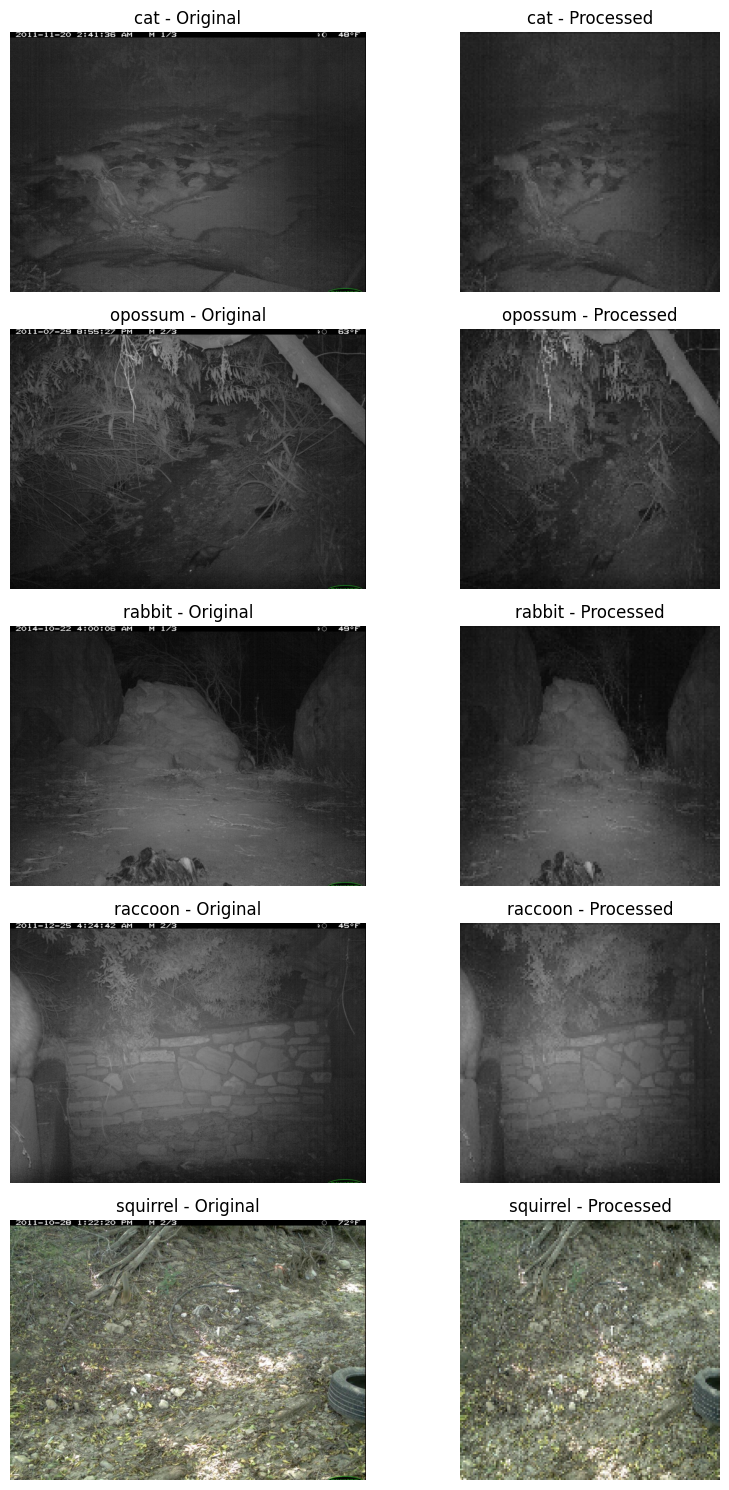

In [16]:

from PIL import Image

# Select one image per species
samples = (
    train_df.groupby("species")
    .sample(n=1, random_state=42)
)

fig, axes = plt.subplots(
    len(samples), 2, figsize=(9, 15)
)

for row, (_, sample) in enumerate(samples.iterrows()):
    # Original image
    original = Image.open(sample["image_path"]).convert("RGB")

    # Processed image
    processed, label = preprocess_image(
        tf.constant(sample["image_path"]),
        tf.constant(sample["label"])
    )

    axes[row, 0].imshow(original)
    axes[row, 0].set_title(
        f"{sample['species']} - Original"
    )

    axes[row, 1].imshow(processed.numpy())
    axes[row, 1].set_title(
        f"{sample['species']} - Processed"
    )

    for ax in axes[row]:
        ax.axis("off")

plt.tight_layout()
plt.show()


In [17]:

def make_dataset(dataframe, training=False):
    dataset = tf.data.Dataset.from_tensor_slices((
        dataframe["image_path"].values,
        dataframe["label"].values
    ))

    dataset = dataset.map(
        preprocess_image,
        num_parallel_calls=tf.data.AUTOTUNE
    )

    if training:
        dataset = dataset.shuffle(1000)

    return dataset.batch(32).prefetch(tf.data.AUTOTUNE)


train_ds = make_dataset(train_df, training=True)
val_ds = make_dataset(validation_df)
test_ds = make_dataset(testing_df)


**Data Preparation:** I selected five backyard animal classes from Caltech Camera Traps, removed overlapping validation sequences, and prepared the image paths and labels. Each image is cropped to remove camera timestamps, resized to 160 × 160, and normalized before being passed to the CNN in batches of 32.